# Введение
Обучим модель бинарной классификации изображений по стилю одежды на основе небольшого датасета. В качестве меток классов возьмем стиль минимализм и любые другие отличные от него стили. Сам стиль характеризуется простотой форм, однородностью, спокойными цветами, качественными материалами, отсутствием декора. Стиль можно также описать как классический, деловой, строгий, дорогой. Выразительность достигается не за счет визуального шума, яркости и акцентов, а внимательного подбора и сочетания простых линий, текстур, фактуры, форм и цветовых оттенков. Для задачи машинного обучения, в качестве признаков могут выступать однородность изображения, отсутствие частых контрастных переходов, характерная цветовая палитра из естественных неярких цветов, белого и черного, прямые и плавные линии контуров.

# Импорт библиотек

In [57]:
# импортируем необходимые библиотеки
import os #для работы с файловой системой
import urllib.request #для HTTP-запросов
import matplotlib.pyplot as plt #для визуализации графиков
from PIL import Image #для работы с изображениями

# для подготовки данных и работы с моделью
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

# Загрузка датасета

In [58]:
# Создаем папки для скачивания изображений из интернета
os.makedirs('dataset/minimalism', exist_ok=True)
os.makedirs('dataset/others', exist_ok=True)
os.makedirs('dataset/test', exist_ok=True)

# Ссылки на 10 изображений стиля минимализм
minimalism_urls = [
    "https://i.pinimg.com/1200x/c8/91/c0/c891c0606df0fe5e8c7800e1daf46363.jpg",
    "https://i.pinimg.com/736x/b3/47/fc/b347fcf2443e707781d9cf3637398b19.jpg",
    "https://i.pinimg.com/1200x/b6/15/c7/b615c7983d32545eabceb6df1850623c.jpg",
    "https://i.pinimg.com/1200x/74/36/b5/7436b57d9903b6c88f10a9cb2878db24.jpg",
    "https://i.pinimg.com/736x/14/1c/b6/141cb630bdfd93c9bdf521c290aac6fc.jpg",
    "https://i.pinimg.com/1200x/3b/fb/17/3bfb17f428d6d3e6a81351c0c734a476.jpg",
    "https://i.pinimg.com/736x/66/83/b0/6683b07fee8acc5974edcaaedab06253.jpg",
    "https://i.pinimg.com/1200x/8f/ad/27/8fad278d011413304d8b458528fea533.jpg",
    "https://i.pinimg.com/736x/b1/de/86/b1de869ed1d815818bc406bde30d0c76.jpg",
    "https://i.pinimg.com/736x/ba/f6/20/baf6201e112fc84e4c4c40e3f52d0964.jpg"
]

# Ссылки на 10 изображений других стилей
others_urls = [
    "https://i.pinimg.com/236x/64/38/41/6438416d868125cd0a55c43e439dfdf5.jpg",
    "https://i.pinimg.com/736x/a8/c9/eb/a8c9eb7c33da91f66c4adcc34953b0f7.jpg",
    "https://i.pinimg.com/736x/97/ee/08/97ee0847f827d36c2cb86be028a2b90f.jpg",
    "https://i.pinimg.com/736x/0d/4b/cb/0d4bcb236bc3daa99b916d3f4ba7d9d6.jpg",
    "https://i.pinimg.com/236x/7e/dc/c9/7edcc97e4c3658f7a70d0fd4f0b96bd9.jpg",
    "https://i.pinimg.com/736x/73/75/9e/73759ef275a108ac06cd5b89d955d3b9.jpg",
    "https://i.pinimg.com/736x/e6/d8/49/e6d849be59a8449deed9360e19fc06b8.jpg",
    "https://i.pinimg.com/736x/fa/6f/61/fa6f61253506d011586fbba27a63445b.jpg",
    "https://i.pinimg.com/1200x/e6/6a/21/e66a21b61067db5bd695224b97f16300.jpg",
    "https://i.pinimg.com/736x/46/26/74/462674752c9a357d363b3780ce3ad243.jpg"
]

# Ссылки на 5 новых тестовых картинок для инференса модели
test_urls = [
    "https://i.pinimg.com/736x/ed/0b/e0/ed0be0cefd265ccf0088b21f794ef404.jpg",
    "https://i.pinimg.com/736x/9a/70/1e/9a701ea7bdda0ee8b13b201112677633.jpg",
    "https://i.pinimg.com/736x/48/b2/9c/48b29cea91dec27bca886aa3d7bd3224.jpg",
    "https://i.pinimg.com/736x/38/07/9a/38079aab52844e6c3f419039df0c382e.jpg",
    "https://i.pinimg.com/736x/d0/55/f9/d055f9716e12ce135137ac8282434cd5.jpg"
]

In [59]:
# определим функцию скачивания изображений
def download_images(url_list, folder_path, prefix):
    """Функция скачивает картинки по ссылкам и сохраняет их под порядковыми номерами."""
    
    # Добавляем user agent, чтобы сервера не блокировали автоматические запросы скрипта
    opener = urllib.request.build_opener()
    opener.addheaders = [('User-agent', 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)')]
    urllib.request.install_opener(opener)
    
    for idx, url in enumerate(url_list):
        try:
            save_path = os.path.join(folder_path, f"{prefix}_{idx}.jpg")
            urllib.request.urlretrieve(url, save_path)
        except Exception as e:
            print(f"Не удалось скачать {url}. Ошибка: {e}")

In [60]:
# вызовем функцию download_images
print("Запуск скачивания картинок одежды из интернета...")
download_images(minimalism_urls, 'dataset/minimalism', 'min')
download_images(others_urls, 'dataset/others', 'other')
download_images(test_urls, 'dataset/test', 'test_img')
print("=== Датасет успешно скачан и сохранен в папки! ===")

Запуск скачивания картинок одежды из интернета...
=== Датасет успешно скачан и сохранен в папки! ===


# Подготовка данных

In [61]:
# создаем пайплайн трансформации картинок.
# Аугментируем данные
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),               # меняем разрешение изображений под модель EfficientNet-B0
    transforms.RandomHorizontalFlip(p=0.5),      # отражаем по горизонтали
    transforms.RandomRotation(10),               # небольшое вращение
    transforms.ToTensor(),                       # преобразуем в тензор
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # нормализуем изображения под модель EfficientNet-B0
])

In [62]:
# создадим класс на основе PyTorch Dataset для маркировки изображений
class StyleDataset(Dataset):
    """Кастомный класс датасета PyTorch для разметки данных (изображений)."""
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []

        # Индексируем класс 0 (Другие стили)
        other_dir = os.path.join(root_dir, 'others')
        for img in os.listdir(other_dir):
            if img.endswith('.jpg'):
                self.image_paths.append(os.path.join(other_dir, img))
                self.labels.append(0)
        
        # Индексируем класс 1 (Минимализм)
        min_dir = os.path.join(root_dir, 'minimalism')
        for img in os.listdir(min_dir):
            if img.endswith('.jpg'):
                self.image_paths.append(os.path.join(min_dir, img))
                self.labels.append(1)
            
        

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB') # приведение к трехканальному формату
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
        return image, label

# Инициализируем датасет и загрузчик данных с батчами по 8 картинок и перемешиванием
dataset = StyleDataset(root_dir='dataset', transform=train_transforms)
dataloader = DataLoader(dataset, batch_size=8, shuffle=True)

# Настройка и обучение модели

In [63]:
# Выбираем устройство для вычислений: GPU (CUDA) или CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Вычисления выполняются на устройстве: {device}")

# инициализируем предобученную модель EfficientNet_B0
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

Вычисления выполняются на устройстве: cpu


In [64]:
# Получаем количество входных признаков из слоя nn.Linear, 
# который находится внутри контейнера model.classifier по индексу [1]
num_features = model.classifier[1].in_features 

# переопределим слой nn.Linear под 2 выходных класса (Минимализм и Другой)
model.classifier[1] = nn.Linear(num_features, 2)
model = model.to(device) # Переносим модель на вычислительное устройство

In [65]:
# Задаем функцию потерь кросс-энтропию и оптимизатор Adam с шагом 0,0001
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# определим количество эпох обучения и пустые списки для логирования значения функции потерь и точности
epochs = 15
history_loss = []
history_acc = []

In [66]:
# обучим модель
print("\n=== Старт процесса обучения классификатора ===")
model.train() 

for epoch in range(epochs):
    running_loss = 0.0
    correct = 0
    total = 0
    
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad() # Обнуляем градиенты
        outputs = model(images) # Прямой проход
        loss = criterion(outputs, labels) # Расчет ошибки
        loss.backward() # Обратный проход
        optimizer.step() # Обновление весов
        
        # Сбор метрик
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    history_loss.append(epoch_loss)
    history_acc.append(epoch_acc)
    
    print(f"Эпоха [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc*100:.2f}%")


=== Старт процесса обучения классификатора ===
Эпоха [1/15] | Loss: 0.6914 | Accuracy: 50.00%
Эпоха [2/15] | Loss: 0.6156 | Accuracy: 70.00%
Эпоха [3/15] | Loss: 0.5418 | Accuracy: 90.00%
Эпоха [4/15] | Loss: 0.5233 | Accuracy: 90.00%
Эпоха [5/15] | Loss: 0.4391 | Accuracy: 100.00%
Эпоха [6/15] | Loss: 0.4430 | Accuracy: 95.00%
Эпоха [7/15] | Loss: 0.4739 | Accuracy: 75.00%
Эпоха [8/15] | Loss: 0.3708 | Accuracy: 95.00%
Эпоха [9/15] | Loss: 0.2401 | Accuracy: 100.00%
Эпоха [10/15] | Loss: 0.2309 | Accuracy: 100.00%
Эпоха [11/15] | Loss: 0.2638 | Accuracy: 100.00%
Эпоха [12/15] | Loss: 0.1613 | Accuracy: 100.00%
Эпоха [13/15] | Loss: 0.1889 | Accuracy: 100.00%
Эпоха [14/15] | Loss: 0.2193 | Accuracy: 100.00%
Эпоха [15/15] | Loss: 0.1373 | Accuracy: 100.00%


# Визуализация результатов обучения

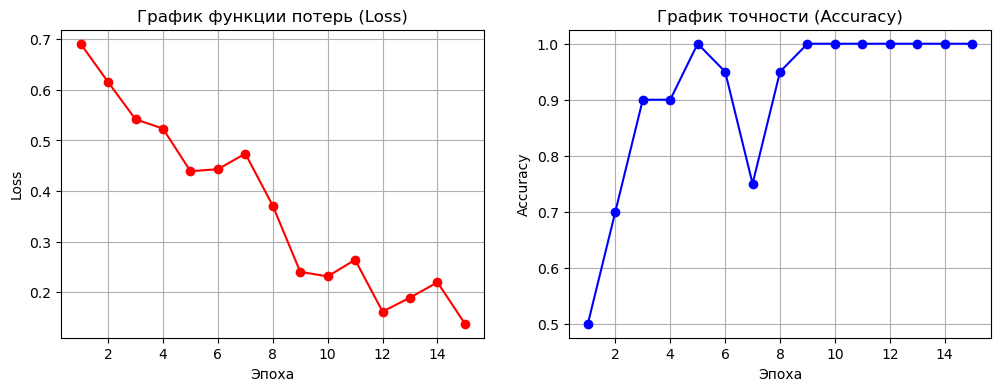

In [67]:
# построим графики функции потерь и точности от эпох обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), history_loss, marker='o', color='red', label='Loss')
plt.title('График функции потерь (Loss)')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), history_acc, marker='o', color='blue', label='Accuracy')
plt.title('График точности (Accuracy)')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

# Тест модели на новых данных

In [68]:
model.eval() # Переводим модель в режим оценки (инференса)

# построим пайплайн трансформации тестовых изображений
test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [71]:
# создадим словари для расшифровки классов и текстового описания
classes = {0: "Другой стиль", 1: "Минимализм"}
test_images_descriptions = [
    "Тест 1: Коричневый блейзер, черная водолазка, синие джинсы, белые кроссовки",
    "Тест 2: Алая блуза с воротником-бантом, алые брюки, черные туфли-лодочки, черный кожаный клатч",
    "Тест 3: Темно-зеленое мини-платье с мелким цветочным принтом, коричневые замшевые полусапожки, коричневый кожаный клатч",
    "Тест 4: Короткая замшевая куртка, молочная футболка, темно-синие джинсы-трубы, темно-коричневые кожаные ботильоны",
    "Тест 5: Кремовый вязаный пуловер, широкие укороченные коричневые брюки-кюлоты, плоские открытые сандалии черной кожи"
]

# Истинные метки стилей для проверки качества работы модели
true_labels = ["Другой стиль", "Другой стиль", "Другой стиль", "Минимализм", "Минимализм"]



=== Проверка классификатора на новых тестовых изображениях ===

[Изображение]: Тест 1: Коричневый блейзер, черная водолазка, синие джинсы, белые кроссовки
 -> Истинный стиль: Другой стиль
 -> Предсказание модели: Другой стиль

[Изображение]: Тест 2: Алая блуза с воротником-бантом, алые брюки, черные туфли-лодочки, черный кожаный клатч
 -> Истинный стиль: Другой стиль
 -> Предсказание модели: Другой стиль

[Изображение]: Тест 3: Темно-зеленое мини-платье с мелким цветочным принтом, коричневые замшевые полусапожки, коричневый кожаный клатч
 -> Истинный стиль: Другой стиль
 -> Предсказание модели: Другой стиль

[Изображение]: Тест 4: Короткая замшевая куртка, молочная футболка, темно-синие джинсы-трубы, темно-коричневые кожаные ботильоны
 -> Истинный стиль: Минимализм
 -> Предсказание модели: Минимализм

[Изображение]: Тест 5: Кремовый вязаный пуловер, широкие укороченные коричневые брюки-кюлоты, плоские открытые сандалии черной кожи
 -> Истинный стиль: Минимализм
 -> Предсказание модели

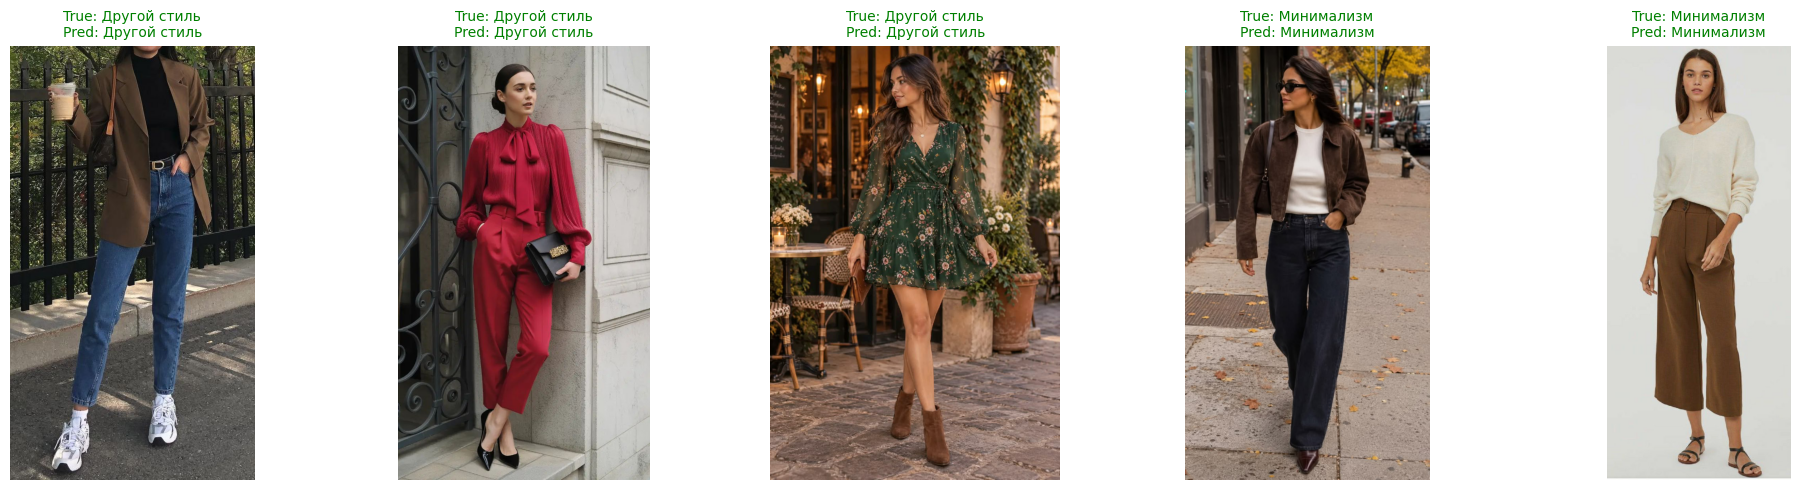

In [72]:
print("\n=== Проверка классификатора на новых тестовых изображениях ===")
# Настройка сетки для вывода изображений (1 строка, 5 колонок)
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

with torch.no_grad(): # отключаем градиенты для ускорения расчетов
    for i in range(5):
        img_path = f'dataset/test/test_img_{i}.jpg'
        
        if os.path.exists(img_path):
            raw_image = Image.open(img_path).convert('RGB')
            tensor_img = test_transforms(raw_image).unsqueeze(0).to(device)
            
            outputs = model(tensor_img)
            _, predicted = torch.max(outputs, 1)
            pred_class = classes[predicted.item()]
            
            print(f"\n[Изображение]: {test_images_descriptions[i]}")
            print(f" -> Истинный стиль: {true_labels[i]}")
            print(f" -> Предсказание модели: {pred_class}")
            
            axes[i].imshow(raw_image)
            
            # Если предсказание верное — пишем зеленым цветом, если ошиблась — красным
            title_color = 'green' if pred_class == true_labels[i] else 'red'
            
            axes[i].set_title(f"True: {true_labels[i]}\nPred: {pred_class}", color=title_color, fontsize=10)
            axes[i].axis('off') 
        else:
            axes[i].text(0.5, 0.5, 'Файл не найден', ha='center', va='center')
            axes[i].axis('off')

plt.tight_layout()
plt.show() # Отрисовываем сетку с картинками и прогнозами в Jupyter Notebook

Модель верно определила все пять тестовых изображений

# Отчет о проделанной работе

Данные для датасета были отобраны с сайта Pinterest вручную. Для воспроизводимости результата работы, все ссылки на использованные изображения интегрированны в код проекта для автоматического скачивания и дальнейшей обработки. Т.к. датасет небольшой, проведена аугментация изображений для улучшения качества модели. В качестве модели выбрана EfficientNet-B0 как достаточно простая, чтобы не допустить переобучения на небольшом наборе данных и не требовательна к вычислительной мощности. В качестве гиперпараметров взят размер батча 8, т.к. данных немного. Скорость обучения 0,0001, что ниже стандартного Adam в 0,001, т.к. мы дообучаем предобученную модель и не хотим сбивать ее веса. Количесво эпох взяли 15 - оптимум для быстрой проверки модели. К девятой эпохе значения функции потерь снижается менее 0,3, а точност выходит на стабильные 100%. Точность предсказания на тестовых изображениях также составляет 100%. Однако объем обучающей и тестовой выборки слишком мал, чтобы можно было говорить о хорошо обученой модели для решения реальных задач. Увеличение обучающей и тестовой выборки позволит улучшить качество распознавания и выявить реальные метрики модели. 